# Prática 7 - Dilema bias-variância
**Valentim Soares de Andrade Neto | 2019027210**

Estudo de regressões de graus 1, 2 e 10 para f(x)=10+2x+3x², com x uniforme em [0,10]. Seguimos o código do enunciado: ruído gaussiano de desvio padrão 10 (o texto menciona N(0,1)). Usamos divisão 80/20, semente 42. Depois aumentamos o desvio padrão para 30 e triplicamos a amostra para 300, mantendo a proporção de treino e teste. Não selecionamos hiperparâmetros pelo teste.


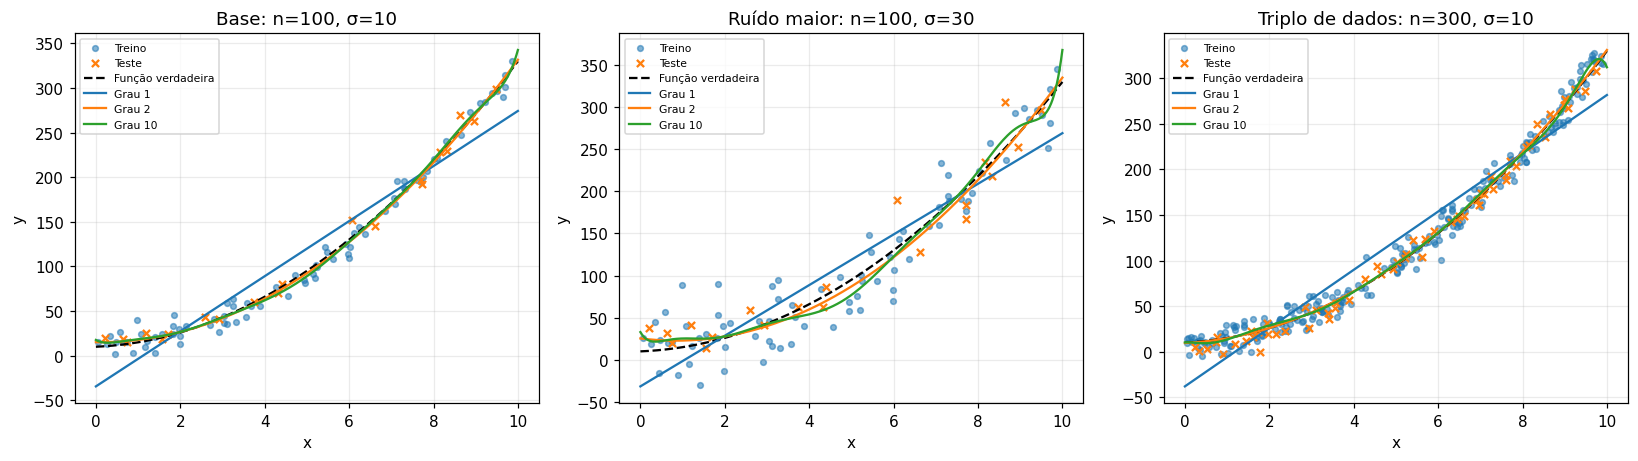

,cenario,n,sigma,grau,mse_treino,mse_teste,r2_treino,r2_teste
0,Base,100,10,1,672.4208,549.9666,0.9232,0.9423
1,Base,100,10,2,81.4715,63.5841,0.9907,0.9933
2,Base,100,10,10,77.0385,66.1204,0.9912,0.9931
3,Ruído maior,100,30,1,1513.9219,1186.2587,0.8352,0.8723
4,Ruído maior,100,30,2,733.2438,572.2565,0.9202,0.9384
5,Ruído maior,100,30,10,693.3461,595.0832,0.9245,0.9359
6,Triplo de dados,300,10,1,611.2513,429.2420,0.9364,0.9501
7,Triplo de dados,300,10,2,105.2295,66.6437,0.9890,0.9922
8,Triplo de dados,300,10,10,99.0179,78.6899,0.9897,0.9908


In [1]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from IPython.display import display
OUT = Path('output'); FIG = OUT/'figuras'; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})
GRAUS = [1, 2, 10]
def f(x): return 10 + 2*x + 3*x**2
def dados(n, sigma, seed):
    rng = np.random.RandomState(seed)
    x = rng.rand(n, 1)*10
    return x, f(x).ravel() + rng.normal(0, sigma, n)
def modelo(grau):
    return make_pipeline(PolynomialFeatures(grau, include_bias=False), LinearRegression())
def z(x): return (x-5)/5
def salvar(nome):
    plt.savefig(FIG/(nome+'.png'), dpi=170, bbox_inches='tight'); plt.show(); plt.close()
cenarios = [('Base', 100, 10), ('Ruído maior', 100, 30), ('Triplo de dados', 300, 10)]
linhas = []; ajustes = {}; grid = np.linspace(0,10,301).reshape(-1,1)
fig, axes = plt.subplots(1,3,figsize=(15,4.3))
for ax, (nome,n,sigma) in zip(axes, cenarios):
    x,y = dados(n,sigma,42)
    xt,xv,yt,yv = train_test_split(x,y,test_size=.2,random_state=42)
    pd.DataFrame({'x':x.ravel(),'y':y,'f_x':f(x).ravel()}).to_csv(OUT/(nome.replace(' ','_')+'.csv'),index=False)
    ax.scatter(xt,yt,s=14,alpha=.55,label='Treino'); ax.scatter(xv,yv,s=22,marker='x',label='Teste')
    ax.plot(grid,f(grid),color='black',ls='--',label='Função verdadeira')
    for grau in GRAUS:
        m = modelo(grau).fit(z(xt),yt)
        pt,pv = m.predict(z(xt)),m.predict(z(xv))
        linhas.append(dict(cenario=nome,n=n,sigma=sigma,grau=grau,mse_treino=mean_squared_error(yt,pt),mse_teste=mean_squared_error(yv,pv),r2_treino=r2_score(yt,pt),r2_teste=r2_score(yv,pv)))
        ajustes[(nome,grau)] = m
        ax.plot(grid,m.predict(z(grid)),label=f'Grau {grau}',lw=1.5)
    ax.set(title=f'{nome}: n={n}, σ={sigma}',xlabel='x',ylabel='y'); ax.legend(fontsize=7)
plt.tight_layout(); salvar('ajustes')
metricas = pd.DataFrame(linhas); metricas.to_csv(OUT/'metricas.csv',index=False)
display(metricas.round(4))
assert np.isfinite(metricas.select_dtypes('number')).all().all()


## Ajuste e avaliação
Usamos mínimos quadrados sem regularização, com intercepto. A transformação fixa z=(x-5)/5 reduz problemas numéricos das potências de grau 10 e não usa estatísticas do teste. Ela preserva o espaço de polinômios em x. MSE tem unidade de y²; R² compara o erro ao preditor constante. R² pode ser negativo. As métricas de uma única divisão são indicadores de ajuste, não uma estimativa direta do bias ou da variância.

## Repetição dos experimentos e decomposição
Repetimos cada cenário com 200 sementes (0 a 199), incluindo a variação dos dados, ruído e divisão. Os cenários com 100 dados compartilham x, a divisão e os mesmos ruídos padronizados em cada repetição. Avaliamos também as previsões em uma grade fixa de 301 pontos em [0,10], incluindo as bordas. Calculamos bias² como a média de (previsão média - f)² e variância como a média da variância populacional das previsões. A identidade empírica E[(predição-f)²]=bias²+variância é verificada. Somar σ² fornece o MSE esperado contra uma nova resposta ruidosa na grade, cuja distribuição não é exatamente o teste aleatório uniforme.


,cenario,grau,mse_treino_medio,mse_teste_medio,mse_teste_mediano,mse_teste_p90,r2_teste_mediano
0,Base,1,585.455,624.125,592.107,857.654,0.928
1,Base,2,96.445,102.428,98.059,143.459,0.988
2,Base,10,86.736,125.340,113.778,167.475,0.987
3,Ruído maior,1,1368.191,1428.991,1392.992,2063.277,0.842
4,Ruído maior,2,868.001,921.855,882.534,1291.134,0.901
5,Ruído maior,10,780.628,1128.060,1023.998,1507.277,0.888
6,Triplo de dados,1,602.232,605.595,612.382,720.654,0.934
7,Triplo de dados,2,98.417,102.220,102.162,126.421,0.989
8,Triplo de dados,10,94.955,106.610,104.825,130.479,0.988


,cenario,grau,bias2,variancia,ruido,mse_esperado_grade
0,Base,1,506.753,18.633,100,625.386
1,Base,2,0.009,3.950,100,103.959
2,Base,10,0.141,32.609,100,132.751
3,Ruído maior,1,506.805,37.979,900,1444.783
4,Ruído maior,2,0.080,35.547,900,935.627
5,Ruído maior,10,1.271,293.483,900,1194.755
6,Triplo de dados,1,506.681,5.649,100,612.330
7,Triplo de dados,2,0.010,1.342,100,101.352
8,Triplo de dados,10,0.031,5.521,100,105.552


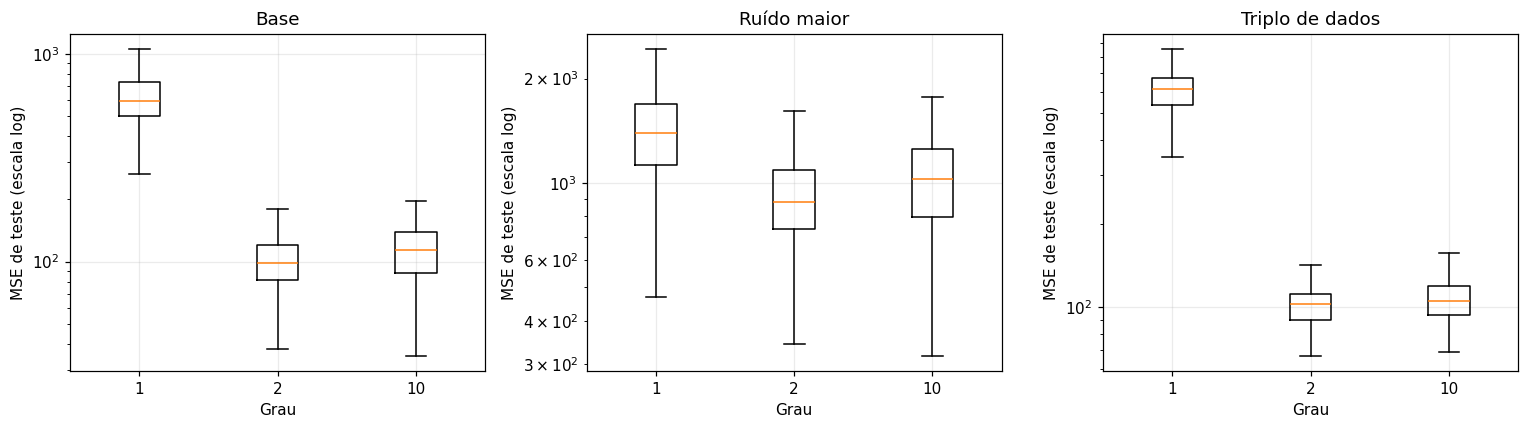

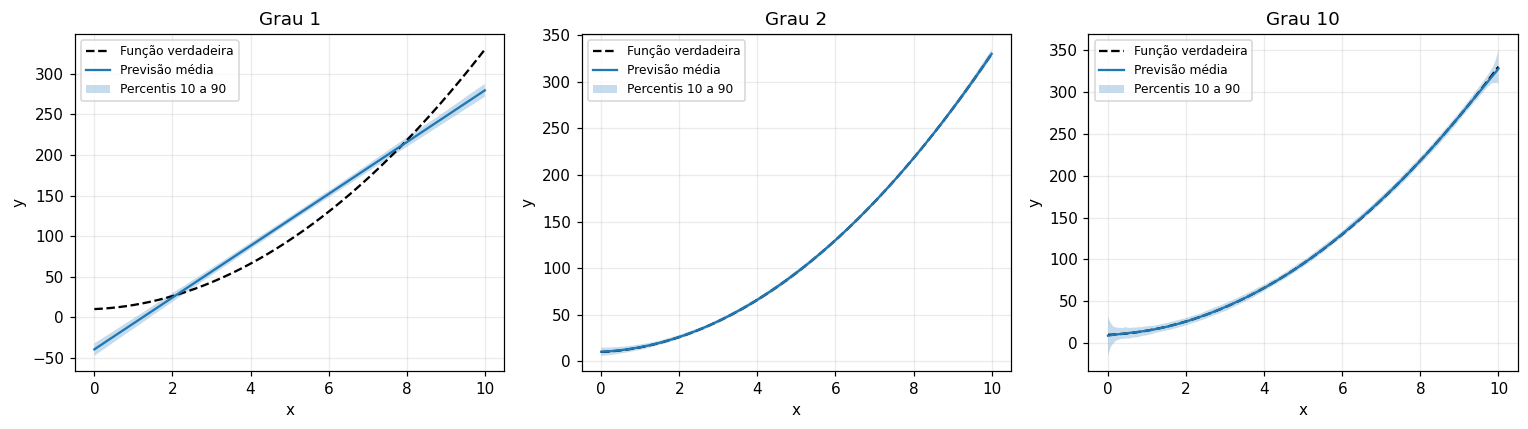

6830

In [2]:
repeticoes = []; decomposicao = []; bandas = {}
for nome,n,sigma in cenarios:
    previsoes = {g: [] for g in GRAUS}
    for seed in range(200):
        x,y = dados(n,sigma,seed)
        xt,xv,yt,yv = train_test_split(x,y,test_size=.2,random_state=seed)
        for grau in GRAUS:
            m = modelo(grau).fit(z(xt),yt)
            previsoes[grau].append(m.predict(z(grid)))
            repeticoes.append(dict(cenario=nome,semente=seed,grau=grau,mse_treino=mean_squared_error(yt,m.predict(z(xt))),mse_teste=mean_squared_error(yv,m.predict(z(xv))),r2_teste=r2_score(yv,m.predict(z(xv)))))
    for grau in GRAUS:
        pred = np.array(previsoes[grau]); media=pred.mean(axis=0)
        bias2 = np.mean((media-f(grid).ravel())**2); var = np.mean(pred.var(axis=0))
        erro = np.mean((pred-f(grid).ravel())**2)
        assert np.isclose(erro,bias2+var,rtol=1e-10,atol=1e-8)
        decomposicao.append(dict(cenario=nome,grau=grau,bias2=bias2,variancia=var,ruido=sigma**2,mse_esperado_grade=bias2+var+sigma**2))
        bandas[(nome,grau)] = (media,np.quantile(pred,.1,axis=0),np.quantile(pred,.9,axis=0))
rep = pd.DataFrame(repeticoes); rep.to_csv(OUT/'repeticoes.csv',index=False)
resumo = rep.groupby(['cenario','grau']).agg(mse_treino_medio=('mse_treino','mean'),mse_teste_medio=('mse_teste','mean'),mse_teste_mediano=('mse_teste','median'),mse_teste_p90=('mse_teste',lambda s:s.quantile(.9)),r2_teste_mediano=('r2_teste','median')).reset_index()
resumo.to_csv(OUT/'resumo_repeticoes.csv',index=False)
dec = pd.DataFrame(decomposicao); dec.to_csv(OUT/'decomposicao.csv',index=False)
display(resumo.round(3)); display(dec.round(3))
fig, axes = plt.subplots(1,3,figsize=(14,4))
for ax,(nome,n,sigma) in zip(axes,cenarios):
    sub=rep[rep.cenario==nome]
    ax.boxplot([sub[sub.grau==g].mse_teste for g in GRAUS],tick_labels=['1','2','10'],showfliers=False)
    ax.set(yscale='log',xlabel='Grau',ylabel='MSE de teste (escala log)',title=nome)
plt.tight_layout(); salvar('repeticoes')
fig, axes=plt.subplots(1,3,figsize=(14,4))
for ax,grau in zip(axes,GRAUS):
    media,lo,hi=bandas[('Base',grau)]
    ax.plot(grid,f(grid),'k--',label='Função verdadeira'); ax.plot(grid,media,label='Previsão média')
    ax.fill_between(grid.ravel(),lo,hi,alpha=.25,label='Percentis 10 a 90')
    ax.set(title=f'Grau {grau}',xlabel='x',ylabel='y'); ax.legend(fontsize=8)
plt.tight_layout(); salvar('estabilidade')
resultados={'metricas':metricas.to_dict('records'),'resumo':resumo.to_dict('records'),'decomposicao':dec.to_dict('records'),'versoes':{'Python':platform.python_version(),'NumPy':np.__version__,'pandas':pd.__version__,'scikit-learn':sklearn.__version__},'repeticoes':200}
(OUT/'resultados.json').write_text(json.dumps(resultados,indent=2,ensure_ascii=False),encoding='utf-8')


## Discussão dos resultados
O grau 1 não representa a curvatura da função geradora, apresentando subajuste e alto bias. O grau 2 contém a relação verdadeira e oferece o equilíbrio adequado. O grau 10 também contém essa relação, mas seus termos adicionais ajustam flutuações do ruído e aumentam a sensibilidade à amostra, especialmente nas bordas. O MSE de treino nunca deve aumentar com o grau, salvo erro numérico, pois os espaços dos modelos são encaixados.

Um grau 10 não é obrigado a ter um teste ruim em uma única divisão: use as tabelas executadas para identificar o vencedor da divisão 42. As repetições e a decomposição permitem discutir a maior variância sem presumir o resultado. Valores extremos explicam diferenças entre média, mediana e percentil 90; o boxplot omite apenas a exibição dos pontos extremos, que continuam nas estatísticas.

Aumentar σ de 10 para 30 multiplica a variância do ruído por nove. O erro irredutível cresce e os coeficientes tornam-se mais instáveis. Triplicar os dados aumenta treino de 80 para 240 e teste de 20 para 60. Mais treino tende a reduzir a variância dos estimadores, mas não corrige a incapacidade estrutural do grau 1 nem elimina o ruído. As amostras de 100 e 300 não são aninhadas; por isso mudanças na divisão individual também refletem a composição da amostra. As repetições apoiam a comparação.

O relatório PDF apresenta as métricas, as respostas às sete perguntas e a interpretação quantitativa. Limitações: simulação unidimensional, domínio conhecido, 200 repetições e grade finita; nenhuma afirmação de desempenho universal ou extrapolação fora de [0,10].


In [3]:
for nome,_,_ in cenarios:
    v=metricas[metricas.cenario==nome].sort_values('grau')
    assert np.all(np.diff(v.mse_treino) <= 1e-6)
assert len(rep)==1800 and len(metricas)==9
assert np.isfinite(dec.select_dtypes('number')).all().all()
print('Verificações: métricas finitas, 1.800 ajustes, MSE de treino não crescente e decomposição correta.')


Verificações: métricas finitas, 1.800 ajustes, MSE de treino não crescente e decomposição correta.
